# Лабораторна робота 3

**Виконала:** Проніна Катерина Сергіївна

**Група:** КМ-51

**Датасет:** DS1 (з лабораторної роботи №2)

## Мета роботи

Вивчити алгоритми побудови опуклої оболонки, їх характеристики, властивості та сфери застосування. Знайти опуклу оболонку заданого датасету, зберегти її як окремий датасет та відобразити разом з вихідними точками.

## Хід роботи

- Вивчити алгоритми побудови опуклої оболонки.
- Використати датасет **DS1** з лабораторної роботи №2 (текстовий файл з парами цілих чисел - координатами точок).
- Реалізувати побудову опуклої оболонки, порівняти два алгоритми та перевірити результат стороннім методом.
- Відобразити оболонку відрізками синього кольору разом з точками вихідного датасету на полотні 960×540 пкс.
- Зберегти оболонку як окремий датасет та результат - у графічний файл.

### Теоретичні відомості

**Опукла оболонка** скінченної множини точок на площині - це найменший опуклий многокутник, який містить усі точки множини (уявіть гумову стрічку, натягнуту навколо цвяхів, забитих у кожну точку).

**Властивості:**
- оболонка є опуклим многокутником, усі її вершини — точки вихідної множини;
- вона має мінімальну площу та мінімальний периметр серед усіх опуклих фігур, що містять множину;
- не залежить від порядку точок у наборі; при афінних перетвореннях вершини оболонки переходять у вершини оболонки.

**Основні алгоритми** (n — кількість точок, h — кількість вершин оболонки):

| Алгоритм | Ідея | Складність |
|---|---|---|
| Джарвіса (gift wrapping) | від поточної вершини обирається точка, відносно якої всі інші лежать з одного боку | O(n·h) |
| Грехема / Ендрю (monotone chain) | сортування точок + стек, що відкидає «ліві/праві» повороти; нижній і верхній ланцюги будуються окремо | O(n log n) |
| QuickHull | «розділяй і володарюй», схожий на швидке сортування | у середньому O(n log n), у гіршому O(n²) |
| Чана (Chan) | поєднує Грехема та Джарвіса | O(n log h) |

**Сфери застосування:** комп'ютерна графіка та розпізнавання образів, геоінформаційні системи, виявлення зіткнень у іграх та робототехніці, статистика (виявлення викидів), оцінка діаметра множини, планування шляху.

Нижче реалізовано **алгоритм Ендрю (monotone chain)** як основний, **алгоритм Джарвіса** — для порівняння, а також виконано перевірку за допомогою `scipy.spatial.ConvexHull`.

## Необхідно написати програму, яка:

1. Зчитує датасет з файлу;
2. Знаходить опуклу оболонку і зберігає її у вигляді окремого датасету;
3. Встановлює розміри вікна (полотна 0 - canvas size) **960×540** пкс;
4. Відображає опуклу оболонку за допомогою відрізків синього кольору;
5. Відображає точки вихідного датасету разом з опуклою оболонкою;
6. Виводить результати у файл графічного формату (PNG).

## Програма

### 1. Імпорт бібліотек

In [9]:
from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull   # лише для перевірки власної реалізації
from PIL import Image

### 2. Зчитування датасету

In [10]:
data_file = Path("DS1.txt")
output_dir = Path(".")

points = np.loadtxt(data_file, dtype=int)   # кожен рядок файлу: "x y"
print(f"Зчитано {len(points)} точок з файлу {data_file}.")
print(f"Унікальних точок: {len(np.unique(points, axis=0))}")

Зчитано 45915 точок з файлу DS1.txt.
Унікальних точок: 45915


### 3. Алгоритми побудови опуклої оболонки

Допоміжна функція `cross(o, a, b)` - псевдоскалярний (векторний) добуток векторів `OA` та `OB`:
- `> 0` - поворот проти годинникової стрілки (ліворуч),
- `< 0` - за годинниковою стрілкою (праворуч),
- `= 0` - точки лежать на одній прямій.

Координати цілі, тому обчислення точні (без похибок округлення). Обидва алгоритми повертають лише *справжні* вершини оболонки (колінеарні точки на сторонах відкидаються) у порядку **проти годинникової стрілки**, починаючи з найлівішої (серед них - найнижчої) точки.

In [11]:
def cross(o, a, b):
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])


def convex_hull_monotone_chain(pts):
    """Алгоритм Ендрю (monotone chain), O(n log n)."""
    pts = sorted(set(map(tuple, pts)))          # сортування за (x, y)
    if len(pts) <= 2:
        return pts

    lower = []                                   # нижній ланцюг
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)

    upper = []                                   # верхній ланцюг
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)

    return lower[:-1] + upper[:-1]               # кінці ланцюгів збігаються


def convex_hull_jarvis(pts):
    """Алгоритм Джарвіса (gift wrapping), O(n·h)."""
    pts = list(set(map(tuple, pts)))
    start = min(pts)                             # найлівіша (потім найнижча) точка — точно у оболонці
    hull, p = [], start
    while True:
        hull.append(p)
        q = pts[0] if pts[0] != p else pts[1]
        for r in pts:
            c = cross(p, q, r)
            # r правіше за p→q, або колінеарна, але далі від p — замінюємо q
            if c < 0 or (c == 0 and (r[0]-p[0])**2 + (r[1]-p[1])**2 > (q[0]-p[0])**2 + (q[1]-p[1])**2):
                q = r
        p = q
        if p == start:
            break
    return hull

### 4. Побудова оболонки, порівняння алгоритмів та перевірка

In [12]:
t0 = perf_counter()
hull_list = convex_hull_monotone_chain(points.tolist())
t_monotone = perf_counter() - t0

t0 = perf_counter()
hull_jarvis = convex_hull_jarvis(points.tolist())
t_jarvis = perf_counter() - t0

hull = np.array(hull_list)                       # опукла оболонка як окремий датасет (N_h × 2)


def polygon_area(h):                             # формула площі Гауса (shoelace)
    xs, ys = h[:, 0], h[:, 1]
    return 0.5 * abs(int(np.dot(xs, np.roll(ys, -1))) - int(np.dot(ys, np.roll(xs, -1))))


def polygon_perimeter(h):
    d = np.roll(h, -1, axis=0) - h
    return float(np.hypot(d[:, 0], d[:, 1]).sum())


# перевірка за допомогою scipy (Qhull)
sp = ConvexHull(points)
same_vertices = set(map(tuple, points[sp.vertices].tolist())) == set(hull_list)

print(f"Кількість вершин оболонки: {len(hull)}")
print(f"Площа оболонки:    {polygon_area(hull):.1f}  (scipy: {sp.volume:.1f})")
print(f"Периметр оболонки: {polygon_perimeter(hull):.2f}  (scipy: {sp.area:.2f})")
print()
print(f"Monotone chain (Ендрю): {t_monotone * 1000:8.1f} мс")
print(f"Джарвіс:                {t_jarvis * 1000:8.1f} мс")
print(f"Обидва алгоритми дали однакову оболонку: {hull_list == hull_jarvis}")
print(f"Збігається з scipy.spatial.ConvexHull:   {same_vertices}")

Кількість вершин оболонки: 36
Площа оболонки:    204733.5  (scipy: 204733.5)
Периметр оболонки: 1763.58  (scipy: 1763.58)

Monotone chain (Ендрю):     86.1 мс
Джарвіс:                   679.4 мс
Обидва алгоритми дали однакову оболонку: True
Збігається з scipy.spatial.ConvexHull:   True


### 5. Збереження оболонки як окремого датасету

Формат файлу такий самий, як і вихідного датасету: у кожному рядку пара цілих чисел `x y`.

In [13]:
np.savetxt(output_dir / "hull_DS1.txt", hull, fmt="%d")
print(f"Оболонку ({len(hull)} вершин) збережено у hull_DS1.txt.")
print(hull[:5])

Оболонку (36 вершин) збережено у hull_DS1.txt.
[[174 292]
 [233  59]
 [234  57]
 [235  56]
 [238  55]]


### 6. Відображення результату

Полотно 960×540 пкс, початок координат (0; 0) - у нижньому лівому куті. Точки вихідного датасету - чорні, опукла оболонка - відрізки синього кольору.

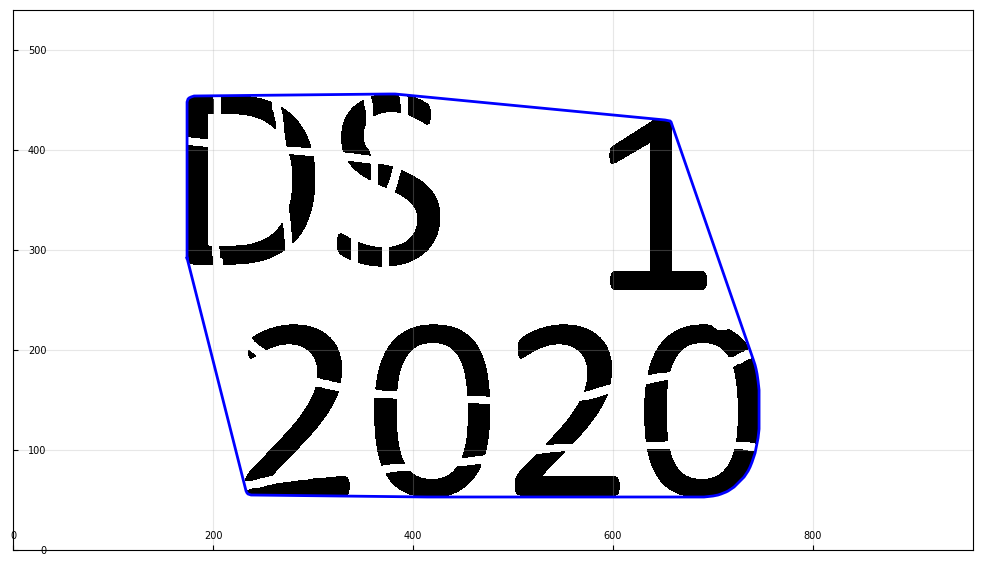

Збережено hull_result.png (960 × 540 пкс).


In [14]:
CANVAS_W, CANVAS_H, DPI = 960, 540, 100

fig = plt.figure(figsize=(CANVAS_W / DPI, CANVAS_H / DPI), dpi=DPI)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, CANVAS_W)
ax.set_ylim(0, CANVAS_H)

# точки вихідного датасету
ax.scatter(points[:, 0], points[:, 1], s=1.5, c="black", marker="s", linewidths=0)

# опукла оболонка — замкнена ламана з відрізків синього кольору
closed = np.vstack([hull, hull[:1]])
ax.plot(closed[:, 0], closed[:, 1], color="blue", linewidth=2, solid_joinstyle="miter")

ax.grid(True, alpha=0.3)
ax.tick_params(direction="in", labelsize=7)
ax.tick_params(axis="x", pad=-14)
ax.tick_params(axis="y", pad=-24)

fig.savefig(output_dir / "hull_result.png", dpi=DPI)
plt.show()

with Image.open(output_dir / "hull_result.png") as img:
    print(f"Збережено hull_result.png ({img.width} × {img.height} пкс).")

## Звіт: опис ходу роботи

1. Вивчено алгоритми побудови опуклої оболонки (Джарвіса, Грехема/Ендрю, QuickHull, Чана), їх складність, властивості та сфери застосування.
2. Датасет **DS1** з лабораторної роботи №2 зчитано з текстового файлу в масив `numpy`.
3. Реалізовано два алгоритми: **monotone chain (Ендрю)** зі складністю O(n log n) та **Джарвіса** зі складністю O(n·h). Для перевірки правильності результат порівняно з `scipy.spatial.ConvexHull` (Qhull) — вершини, площа та периметр збіглися.
4. Опуклу оболонку збережено окремим датасетом у файл `hull_DS1.txt` (вершини в порядку проти годинникової стрілки, формат `x y`).
5. На полотні 960×540 пкс побудовано точки вихідного датасету (чорні) та опуклу оболонку відрізками синього кольору; результат збережено у `hull_result.png`.

**Використані бібліотеки та методи:**

| Бібліотека | Методи / функції | Призначення |
|---|---|---|
| `numpy` | `loadtxt`, `savetxt`, `unique`, `vstack`, `roll`, `dot`, `hypot` | зчитування/збереження датасетів, обчислення площі та периметра |
| `matplotlib.pyplot` | `figure`, `add_axes`, `set_xlim`, `set_ylim`, `scatter`, `plot`, `savefig`, `show` | відображення точок та оболонки на полотні 960×540 |
| `scipy.spatial` | `ConvexHull` | незалежна перевірка власної реалізації |
| стандартна бібліотека | `time.perf_counter`, `pathlib.Path`, `sorted`, `set` | вимірювання часу, шляхи до файлів, підготовка точок |
| `Pillow` | `Image.open` | перевірка розміру збереженого зображення |